# Stochastic Processes, Monte Carlo, Importance Sampling, and MCMC

**AI Mathematics · 7. Advanced Topics**

Introduce sequences of random variables, Markov chains, Monte Carlo estimates, importance sampling, and MCMC diagnostics.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Understand a Markov chain and stationary distribution.
- Estimate expectations with Monte Carlo.
- Explain importance sampling and Metropolis-Hastings.

In [1]:
import numpy as np

## 1. Stochastic processes and Markov property
A stochastic process is a family of random variables indexed by time or another index. A Markov chain satisfies \(P(X_{t+1}|X_t,\ldots,X_0)=P(X_{t+1}|X_t)\). The state summarizes the information needed to predict the next state under the model.

In [2]:
import numpy as np

P = np.array([[0.8, 0.2], [0.3, 0.7]])  # row-stochastic transition matrix
state_distribution = np.array([1.0, 0.0])
for step in range(5):
    state_distribution = state_distribution @ P
    print(step+1, state_distribution, "sum:", state_distribution.sum())

1 [0.8 0.2] sum: 1.0
2 [0.7 0.3] sum: 1.0000000000000002
3 [0.65 0.35] sum: 1.0000000000000002
4 [0.625 0.375] sum: 1.0000000000000002
5 [0.6125 0.3875] sum: 1.0000000000000002


## 2. Stationary distributions
A stationary distribution \(\pi\) satisfies \(\pi P=\pi\). For a finite irreducible and aperiodic chain, the distribution often converges to a unique stationary distribution. Check row/column convention: this example uses row distributions and rows of \(P\) as transition probabilities.

In [3]:
eigenvalues, eigenvectors = np.linalg.eig(P.T)
idx = np.argmin(np.abs(eigenvalues - 1))
pi = np.real(eigenvectors[:, idx])
pi = pi / pi.sum()
print("stationary distribution:", pi)
print("check pi P = pi:", pi @ P)

stationary distribution: [0.6 0.4]
check pi P = pi: [0.6 0.4]


## 3. Monte Carlo estimation
Monte Carlo estimates an expectation by averaging samples. Its standard error often decreases like \(1/\sqrt{N}\), so reducing error by a factor of ten may require roughly one hundred times as many independent samples.

In [4]:
rng = np.random.default_rng(123)
for n in [100, 1_000, 10_000, 100_000]:
    samples = rng.uniform(0, 1, n)
    estimate = np.mean(samples**2)
    print(n, estimate, "absolute error:", abs(estimate - 1/3))

100 0.310009764483623 absolute error: 0.02332356884971032
1000 0.3406891294505746 absolute error: 0.007355796117241298
10000 0.32603975028115706 absolute error: 0.007293583052176256
100000 0.3337068886283705 absolute error: 0.00037355529503718676


## 4. Importance sampling
If samples come from proposal distribution \(q(x)\) rather than target distribution \(p(x)\), importance weights \(w(x)=p(x)/q(x)\) can correct the expectation when support conditions hold. Highly variable weights can produce a low effective sample size and unreliable estimates.

In [5]:
# Discrete importance sampling example. Target expectation under p; samples drawn from q.
p = np.array([0.1, 0.2, 0.7])
q = np.array([0.3, 0.3, 0.4])
f = np.array([0.0, 1.0, 3.0])
exact = np.sum(p*f)
weights = p/q
rng = np.random.default_rng(4)
idx = rng.choice(3, size=50_000, p=q)
weighted_estimate = np.mean(weights[idx]*f[idx])
print("exact:", exact, "importance estimate:", weighted_estimate)

exact: 2.3 importance estimate: 2.3034799999999995


## 5. Metropolis-Hastings MCMC
MCMC constructs a chain whose stationary distribution is the target distribution. In Metropolis-Hastings, propose a state and accept it with a probability based on the target density and proposal ratio. Samples are dependent, so effective sample size is smaller than the number of iterations in many cases.

In [6]:
# Minimal random-walk Metropolis sampler for a standard normal target.
rng = np.random.default_rng(7)
def log_target(x):
    return -0.5*x*x  # constants cancel in acceptance ratio

current = 0.0
samples = []
accepted = 0
for _ in range(12_000):
    proposal = current + rng.normal(scale=1.0)
    log_alpha = log_target(proposal) - log_target(current)
    if np.log(rng.uniform()) < min(0.0, log_alpha):
        current = proposal
        accepted += 1
    samples.append(current)
samples = np.array(samples[2000:])  # discard a short burn-in for demonstration
print("sample mean:", samples.mean())
print("sample variance:", samples.var())
print("acceptance rate:", accepted/12_000)

sample mean: 0.0328317813589446
sample variance: 0.9848037691927051
acceptance rate: 0.7025


## 6. Markov Decision Processes (MDPs)
An MDP models sequential decisions with states, actions, transition probabilities, rewards, and a discount factor. Reinforcement learning seeks a policy that maximizes expected cumulative reward. This is a conceptual bridge; solving an MDP is different from merely simulating a Markov chain.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: Markov chains, sampling, and Monte Carlo error

A Markov chain moves between states according to transition probabilities. Monte Carlo methods estimate expectations using samples; the estimate usually becomes more stable as the effective sample size increases. Sequential samples may be correlated, so the nominal number of MCMC draws is not always the same as the effective sample size.

empirical transition frequencies:
 col_0      0      1
row_0              
0      0.850  0.150
1      0.222  0.778


20_stochastic_processes_sampling_mcmc.ipynb:cell16:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


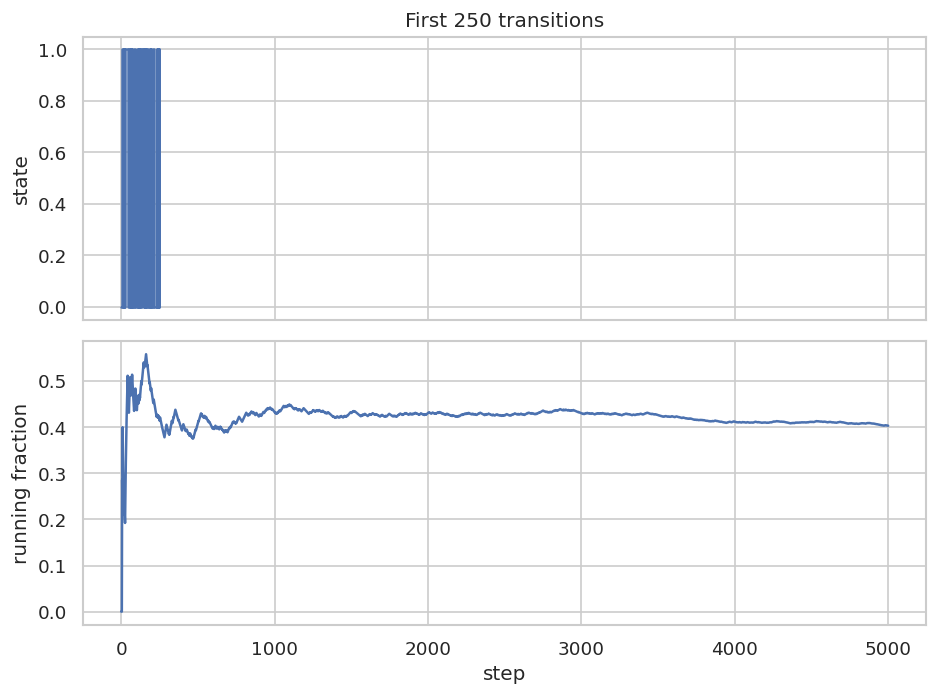

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_mc_rng = np.random.default_rng(47)
viz_mc_P = np.array([[0.85, 0.15], [0.25, 0.75]])
viz_mc_states = np.zeros(5000, dtype=int)
for i in range(1, len(viz_mc_states)):
    viz_mc_states[i] = viz_mc_rng.choice([0, 1], p=viz_mc_P[viz_mc_states[i-1]])
viz_mc_df = pd.DataFrame({"step": np.arange(len(viz_mc_states)), "state": viz_mc_states})
viz_mc_df["running fraction in state 1"] = viz_mc_df["state"].expanding().mean()
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(viz_mc_df["step"].iloc[:250], viz_mc_df["state"].iloc[:250], drawstyle="steps-post")
axes[0].set_ylabel("state"); axes[0].set_title("First 250 transitions")
axes[1].plot(viz_mc_df["step"], viz_mc_df["running fraction in state 1"])
axes[1].set_xlabel("step"); axes[1].set_ylabel("running fraction")
plt.tight_layout(); plt.show()
print("empirical transition frequencies:\n", pd.crosstab(viz_mc_states[:-1], viz_mc_states[1:], normalize="index").round(3))

### Monte Carlo estimation of an expectation

For independent samples \(X_i\), the sample average estimates \(E[X]\). The following example samples from a standard normal distribution, whose theoretical mean is zero. Running averages fluctuate but generally settle as the sample count grows.

20_stochastic_processes_sampling_mcmc.ipynb:cell18:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
20_stochastic_processes_sampling_mcmc.ipynb:cell18:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


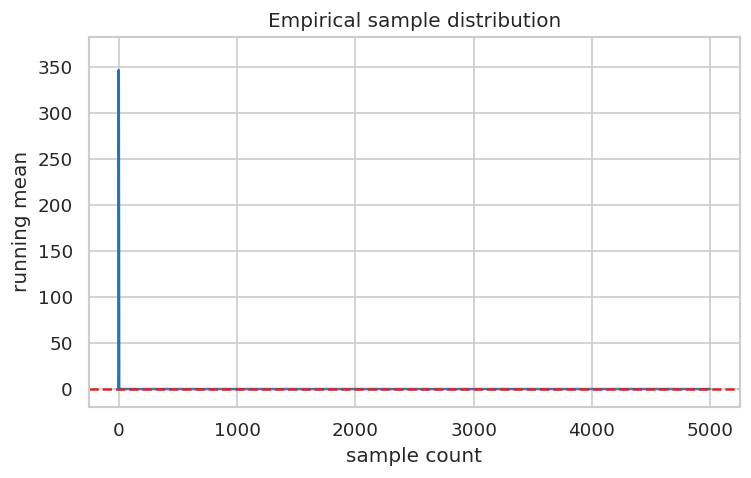

In [8]:
viz_mc_iid = viz_mc_rng.normal(size=5000)
viz_mc_avg = np.cumsum(viz_mc_iid)/np.arange(1, len(viz_mc_iid)+1)
viz_mc_error = np.abs(viz_mc_avg)
viz_mc_mean_df = pd.DataFrame({"sample count": np.arange(1, len(viz_mc_iid)+1), "running mean": viz_mc_avg, "absolute error from zero": viz_mc_error})
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_mc_mean_df["sample count"], viz_mc_mean_df["running mean"])
ax.axhline(0, color="tab:red", linestyle="--"); ax.set_xlabel("sample count"); ax.set_ylabel("running mean")
ax.set_title("Monte Carlo estimate of E[X] for X ~ Normal(0, 1)"); plt.show()
sns.histplot(viz_mc_iid, bins=40, kde=True, color="tab:blue")
plt.title("Empirical sample distribution"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Verify that each row of a transition matrix sums to one.

In [9]:
P = np.array([[0.7, 0.3], [0.1, 0.9]])
print(P.sum(axis=1))

[1. 1.]


### Exercise 2
Exercise 2: Estimate E[X] for X~Uniform(0,1) with 5,000 samples.

In [10]:
rng = np.random.default_rng(0)
print(rng.uniform(size=5000).mean())

0.4986354374669263


## Key takeaways
- Markov chains encode sequential dependence through transition probabilities.
- Monte Carlo accuracy improves slowly with sample count.
- Importance sampling and MCMC require diagnostics; generated samples are not automatically trustworthy.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.